# Scripts and reviews: what they say about profit

This notebook works through the group's notes on scripts and reviews. Every number is computed in a cell
below, from files the scripts in `scripts/screenplays/` and `scripts/reviews/` write to `data/raw/features/`.
Run those first (see the README section *Scripts and reviews*). Review text and screenplays never leave
`data/raw/`, and no cell prints them.

**Profit** is the gross multiple, worldwide gross divided by budget, on a log scale. It isn't real profit:
marketing isn't in the budget and cinemas keep part of the gross. A **hit** is a film in the top quarter
of the sample by multiple and a **flop** one in the bottom quarter. Both cut-offs are our choice.

| Note | Section |
|---|---|
| Discard reviews and focus on scripts? | 1. What we have |
| What makes a good script: successful vs unsuccessful | 2, 3 and 6 |
| Sentiment in scripts | 4 |
| Other things to extract from scripts | 5 and 6 |
| Weekly reviews vs weekly cinema revenue | 7 |
| Reviews in an embedding space vs profit | 9 |
| Sentiment analysis of reviews | 8 and 10 |

In [1]:
import csv, json, math, re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA = Path("../data/raw")
F = DATA / "features"
SEED = 1
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
HIT, FLOP, OTHER = "#2a9d8f", "#e76f51", "#bbbbbb"

## The sample

The clean theatrical sample uses the same rule as `scripts/imdb/genome_stats.py`: budget and gross both in
US dollars, budget and gross at least $1,000, no rentals-only or regional gross, no streaming distributor,
released before 2026. Both vote tiers (10,000+ votes) are used, because the 100k+ tier has few flops.

In [2]:
m = pd.read_csv(F / "movies_features_10k.csv", dtype={"tconst": str})
ok = ((m.budget_cur == "USD") & (m.gross_cur == "USD") & (m.b >= 1000) & (m.g >= 1000)
      & ~m.gross_flag.fillna("").str.contains("rentals|regional")
      & ~m.distributors.fillna("").str.contains("netflix|amazon|apple|hulu", case=False)
      & (m.y < 2026))
m = m[ok].copy()
m["log_mult"] = np.log(m.g / m.b)
m["log_budget"] = np.log(m.b)
hi, lo = m.log_mult.quantile([0.75, 0.25])
m["group"] = np.where(m.log_mult >= hi, "hit", np.where(m.log_mult <= lo, "flop", "middle"))

sp = pd.read_csv(F / "screenplay_features.csv", dtype={"tconst": str})
rv = pd.read_csv(F / "review_features.csv", dtype={"tconst": str})
d = m.merge(sp, on="tconst", how="left").merge(rv, on="tconst", how="left")
print(f"clean movies {len(m):,}; hit = at least {math.exp(hi):.1f}x budget, flop = at most {math.exp(lo):.2f}x")

clean movies 6,851; hit = at least 4.3x budget, flop = at most 0.91x


## 1. What we have: scripts, reviews, or both?

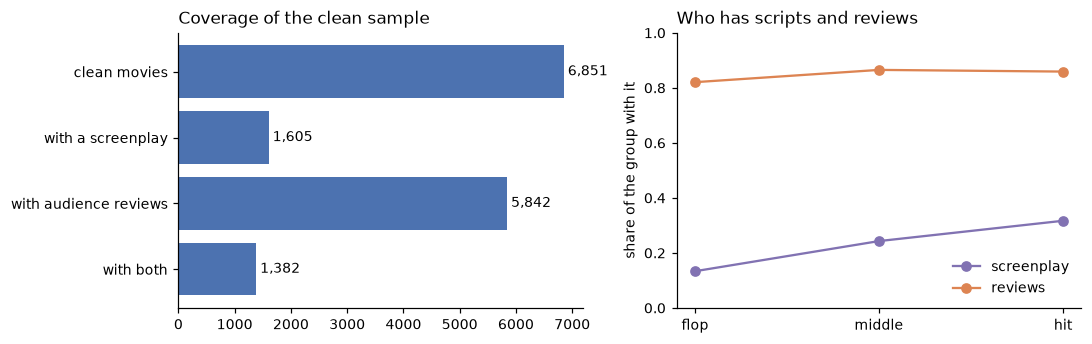

reviews: latest film 2017; screenplays: 1932 to 2023


In [3]:
has_script, has_reviews = d.characters.notna(), d.vader_mean.notna()
counts = {"clean movies": len(d), "with a screenplay": has_script.sum(), "with audience reviews": has_reviews.sum(),
          "with both": (has_script & has_reviews).sum()}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].barh(list(counts)[::-1], list(counts.values())[::-1], color="#4c72b0")
for i, v in enumerate(list(counts.values())[::-1]):
    axes[0].text(v, i, f" {v:,}", va="center")
axes[0].set_title("Coverage of the clean sample", loc="left")
for name, mask, c in [("screenplay", has_script, "#8172b2"), ("reviews", has_reviews, "#dd8452")]:
    share = d[mask].groupby("group").size() / d.groupby("group").size()
    axes[1].plot(["flop", "middle", "hit"], share[["flop", "middle", "hit"]], "o-", color=c, label=name)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("share of the group with it")
axes[1].set_title("Who has scripts and reviews", loc="left"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
yrs = d[has_reviews].y
print(f"reviews: latest film {int(yrs.max())}; screenplays: {int(d[has_script].y.min())} to {int(d[has_script].y.max())}")

Screenplays exist mostly for well-known films, so flops are under-represented among them. Reviews cover
more of the sample but stop at 2017. Dropping reviews would cost the only text that covers flops well,
so the notebook keeps both.

## 2. Hits vs flops: what's different about the script?

In [4]:
FEATS = {"characters": "speaking characters", "density": "network density", "lead_share": "lead's share of lines",
         "centralisation": "degree centralisation", "clustering": "clustering", "modularity": "modularity",
         "line_gini": "inequality of lines", "scenes": "scenes", "words": "words",
         "speeches_per_scene": "speeches per scene", "words_per_speech": "words per speech",
         "dialogue_share": "dialogue share", "sent_mean": "mean sentiment", "sent_swing": "sentiment swing",
         "sent_ending": "ending vs average"}

def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = p[o] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty_like(q); out[o] = np.minimum(q, 1); return out

def rank_partial(y, x, z):
    r = lambda v: stats.rankdata(v)
    Z = np.column_stack([np.ones(len(y))] + [r(c) for c in z.T])
    res = lambda v: r(v) - Z @ np.linalg.lstsq(Z, r(v), rcond=None)[0]
    return stats.pearsonr(res(x), res(y))

s = d[has_script & d.sent_mean.notna()].copy()
hf = s[s.group != "middle"]
rows = []
for f, label in FEATS.items():
    a, b = hf[hf.group == "hit"][f], hf[hf.group == "flop"][f]
    p_mw = stats.mannwhitneyu(a, b).pvalue
    rho, p_part = rank_partial(s.log_mult.values, s[f].values, s[["log_budget", "y"]].values)
    rows.append({"feature": label, "hit median": a.median(), "flop median": b.median(), "p hit vs flop": p_mw,
                 "rho with multiple, net of budget and year": rho, "p partial": p_part})
t = pd.DataFrame(rows)
t["q hit vs flop"], t["q partial"] = bh(t["p hit vs flop"]), bh(t["p partial"])
print(f"{(s.group == 'hit').sum()} hit and {(s.group == 'flop').sum()} flop films with a screenplay")
t.round(3).sort_values("q partial")

540 hit and 228 flop films with a screenplay


,feature,hit median,flop median,p hit vs flop,"rho with multiple, net of budget and year",p partial,q hit vs flop,q partial
3,degree centralisation,0.582,0.638,0.002,-0.097,0.000,0.025,0.002
1,network density,0.263,0.229,0.009,0.088,0.000,0.067,0.003
4,clustering,0.081,0.078,0.055,0.061,0.014,0.276,0.062
12,mean sentiment,0.047,0.044,0.112,0.060,0.016,0.319,0.062
2,lead's share of lines,0.315,0.318,0.128,-0.053,0.033,0.319,0.098
6,inequality of lines,0.668,0.675,0.239,-0.052,0.039,0.449,0.098
7,scenes,124.000,135.000,0.111,-0.045,0.074,0.319,0.159
10,words per speech,9.819,9.779,0.700,-0.042,0.094,0.897,0.177
0,speaking characters,24.000,25.000,0.186,-0.038,0.133,0.399,0.221
11,dialogue share,0.421,0.427,0.600,-0.033,0.182,0.897,0.273


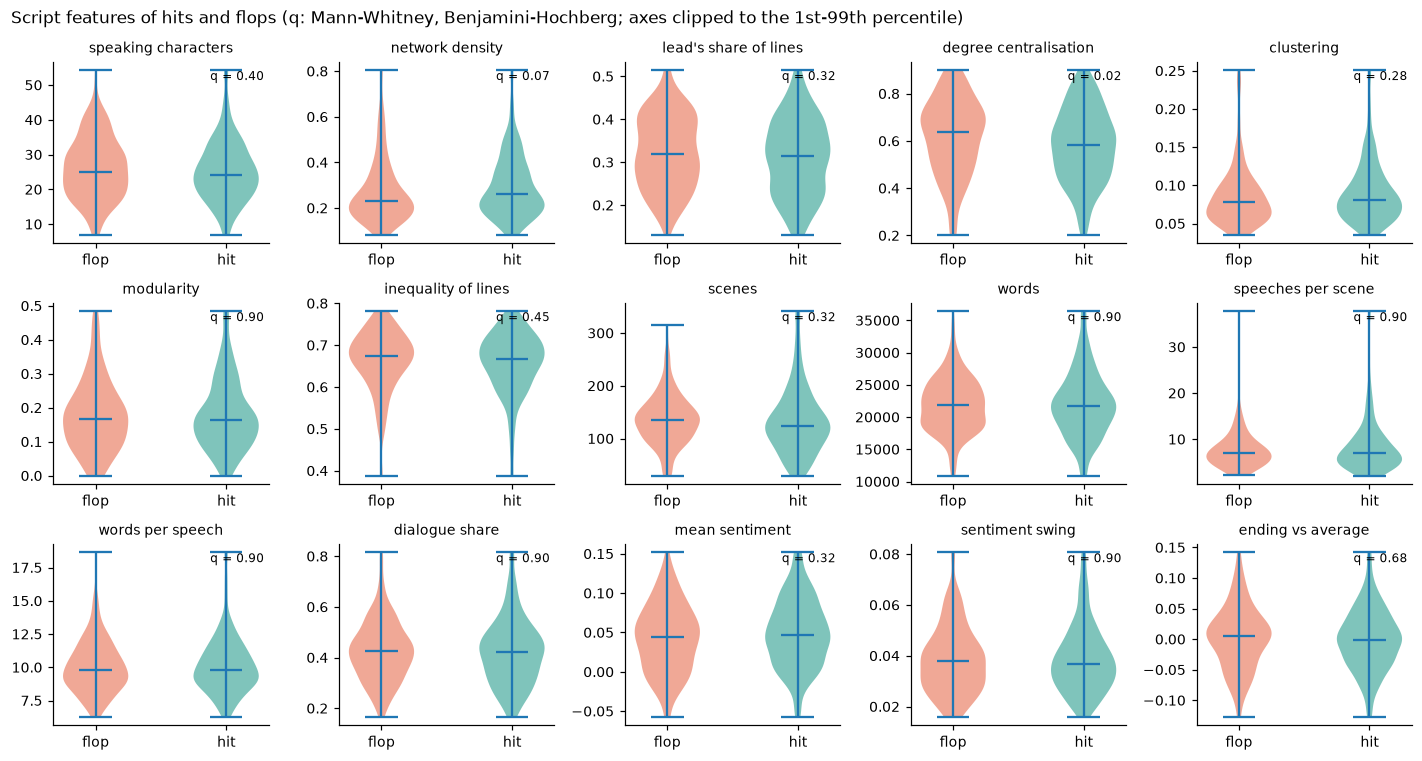

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(13, 7))
for ax, (f, label) in zip(axes.flat, FEATS.items()):
    lo_, hi_ = hf[f].quantile([0.01, 0.99])
    data = [hf[hf.group == g][f].dropna().clip(lo_, hi_) for g in ("flop", "hit")]
    parts = ax.violinplot(data, showmedians=True)
    for body, c in zip(parts["bodies"], (FLOP, HIT)):
        body.set_facecolor(c); body.set_alpha(0.6)
    ax.set_xticks([1, 2], ["flop", "hit"]); ax.set_title(label, fontsize=9)
    q = t.loc[t.feature == label, "q hit vs flop"].item()
    ax.text(0.98, 0.95, f"q = {q:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=8)
fig.suptitle("Script features of hits and flops (q: Mann-Whitney, Benjamini-Hochberg; axes clipped to the 1st-99th percentile)",
             x=0.01, ha="left")
plt.tight_layout(); plt.show()

Read the q-values before the shapes. A raw hit-vs-flop difference can come from budget alone (cheap horror
films are both hits by multiple and short, talky scripts), so the table's partial correlation, which holds
budget and year fixed, is the fairer test.

## 3. What a hit's and a flop's cast look like

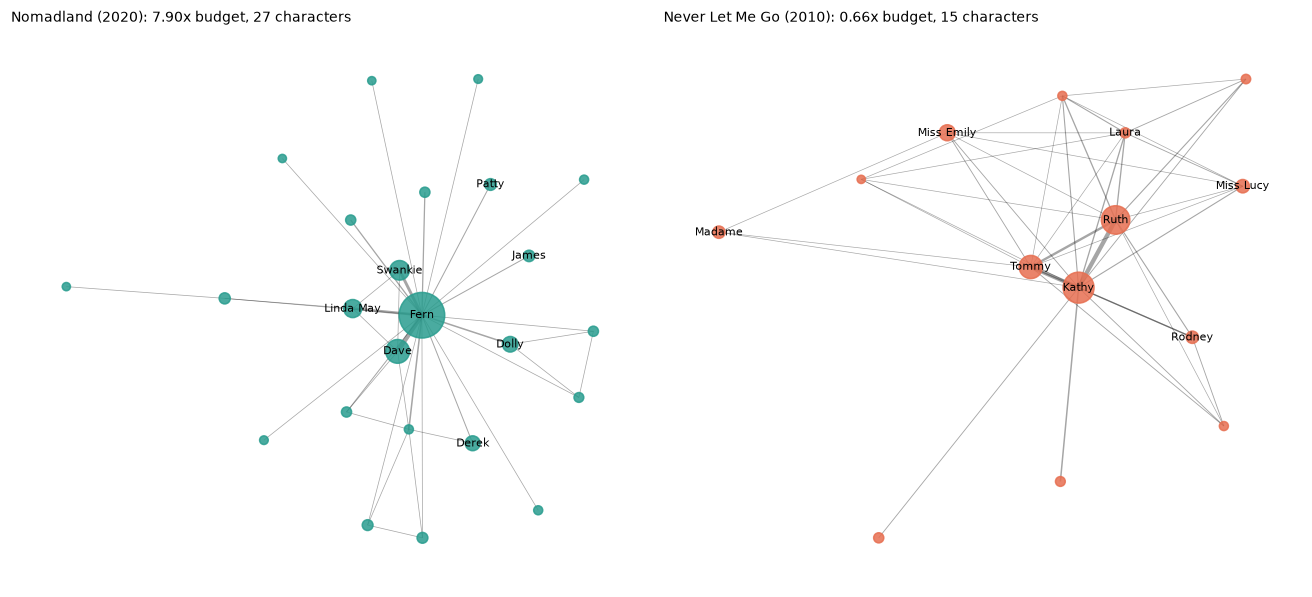

In [6]:
import sys; sys.path.insert(0, "../scripts/screenplays")
import screenplay_features as sf

def script_of(tconst):
    for path in sf.SPLITS:
        with open(DATA / path, encoding="utf8") as fh:
            for line in fh:
                if f'"{tconst}"' in line:
                    r = json.loads(line)
                    if r["imdb_id"] == tconst:
                        return r
# Typical rather than extreme: the hit and the flop closest to their group's median multiple, among
# films with a mid-sized cast and enough scenes for the network to mean something.
big = s[s.characters.between(15, 35) & s.scenes.between(80, 200) & (s.votes >= 100_000)]
def typical(grp):
    g = big[big.group == grp]
    return g.loc[(g.log_mult - g.log_mult.median()).abs().idxmin()]
picks = [typical("hit"), typical("flop")]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, row, c in zip(axes, picks, (HIT, FLOP)):
    scenes, _ = sf.parse(script_of(row.tconst)["script"])
    g, lines = sf.network(scenes)
    g = g.subgraph(max(nx.connected_components(g), key=len)).copy()
    pos = nx.spring_layout(g, weight="weight", seed=SEED)
    w = np.array([g[a][b]["weight"] for a, b in g.edges()])
    nx.draw_networkx_edges(g, pos, ax=ax, width=0.3 + 2.5 * w / w.max(), alpha=0.35)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=[20 + 3 * lines[n] for n in g], node_color=c, alpha=0.85)
    top = sorted(lines, key=lines.get, reverse=True)[:8]
    nx.draw_networkx_labels(g, pos, {n: n.title() for n in top}, ax=ax, font_size=7)
    ax.set_title(f"{row.primaryTitle} ({int(row.y)}): {math.exp(row.log_mult):.2f}x budget, "
                 f"{int(row.characters)} characters", loc="left", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

Node size is lines spoken, edge width is shared scenes, and only the largest connected group of
characters is drawn. The two films are the hit and the flop closest to their group's median multiple, among
films with 100,000+ votes and a mid-sized cast. They illustrate the measures and prove nothing on their own.

## 4. Sentiment arcs

Each speech gets a VADER score, the speeches are cut in order into 40 parts, and a part's mean is one point
of the arc. Below: the average arc of hits and of flops with a bootstrap band. Then the arcs are clustered
by shape (smoothed, z-scored, k-means with 6 groups, after Reagan et al. 2016), and each shape's multiple is
compared.

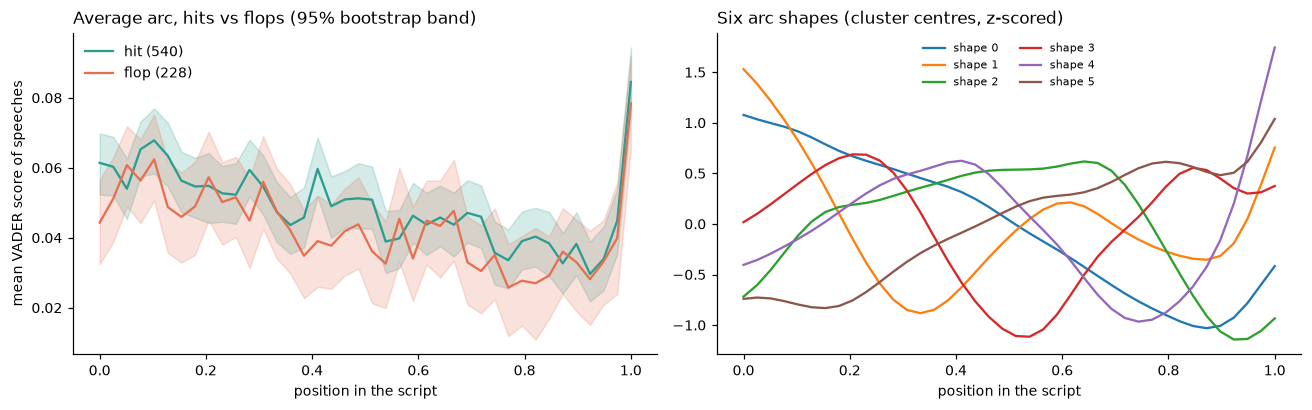

Kruskal-Wallis across shapes, multiple: p = 0.987


,films,median_multiple,hit_share,median_rt
shape,,,,
0,319,2.84,0.35,77.0
1,279,3.15,0.32,75.0
2,270,2.81,0.32,77.0
3,233,2.84,0.39,72.0
4,252,2.83,0.33,71.0
5,243,3.00,0.34,72.0


In [7]:
from scipy.ndimage import gaussian_filter1d
from sklearn.cluster import KMeans

arcs = np.load(F / "screenplay_arcs.npy")
arc_ids = sp[sp.has_arc == 1].tconst.tolist()
A = pd.DataFrame(arcs, index=arc_ids)
x = np.linspace(0, 1, arcs.shape[1])
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for grp, c in (("hit", HIT), ("flop", FLOP)):
    ids = [t for t in s[s.group == grp].tconst if t in A.index]
    M = A.loc[ids].values
    boot = np.array([M[rng.integers(0, len(M), len(M))].mean(0) for _ in range(500)])
    axes[0].plot(x, M.mean(0), color=c, label=f"{grp} ({len(M)})")
    axes[0].fill_between(x, *np.percentile(boot, [2.5, 97.5], axis=0), color=c, alpha=0.2)
axes[0].set_xlabel("position in the script"); axes[0].set_ylabel("mean VADER score of speeches")
axes[0].set_title("Average arc, hits vs flops (95% bootstrap band)", loc="left"); axes[0].legend(frameon=False)

shape = np.array([(lambda v: (v - v.mean()) / (v.std() or 1))(gaussian_filter1d(a, 2.0, mode="nearest")) for a in arcs])
km = KMeans(6, n_init=50, random_state=SEED).fit(shape)
order = np.argsort([c[-10:].mean() - c[:10].mean() for c in km.cluster_centers_])
lab = pd.Series({t: int(np.where(order == l)[0][0]) for t, l in zip(arc_ids, km.labels_)}, name="shape")
for k in range(6):
    axes[1].plot(x, km.cluster_centers_[order[k]], label=f"shape {k}")
axes[1].set_title("Six arc shapes (cluster centres, z-scored)", loc="left")
axes[1].set_xlabel("position in the script"); axes[1].legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

sh = s.join(lab, on="tconst").dropna(subset=["shape"])
by = sh.groupby("shape").agg(films=("tconst", "size"), median_multiple=("log_mult", lambda v: math.exp(v.median())),
                             hit_share=("group", lambda v: (v == "hit").mean()), median_rt=("rt", "median"))
kw = stats.kruskal(*[g.log_mult for _, g in sh.groupby("shape")])
print(f"Kruskal-Wallis across shapes, multiple: p = {kw.pvalue:.3f}")
by.round(2)

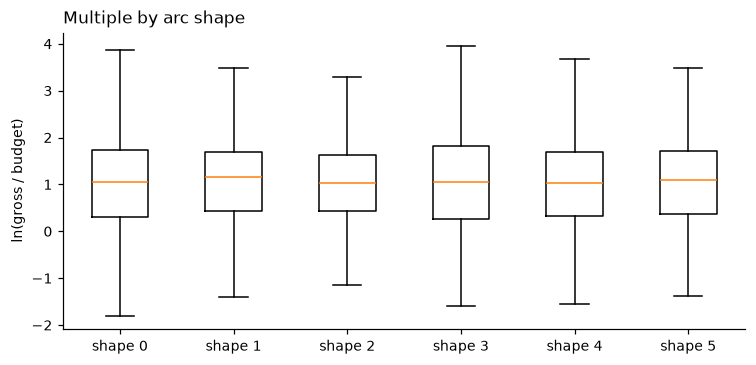

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
groups = [g.log_mult.values for _, g in sh.groupby("shape")]
ax.boxplot(groups, showfliers=False)
ax.set_xticks(range(1, 7), [f"shape {k}" for k in range(6)])
ax.set_ylabel("ln(gross / budget)"); ax.set_title("Multiple by arc shape", loc="left")
plt.show()

Shapes are ordered by their ending: shape 0 ends lowest compared with how it starts, shape 5 highest.
VADER was built for social media text, so it misreads irony and some film dialogue. The arcs are best
read as the tone of what characters say, not of what happens on screen.

## 5. Words that separate hit scripts from flop scripts

Dialogue word counts for hits against flops, scored with the weighted log-odds ratio with an informative
Dirichlet prior (Monroe, Colaresi and Quinn 2008). Words that are part of any character's name are dropped,
because names otherwise top both lists. A word needs to appear in at least 50 screenplays, and slurs are
shown masked.

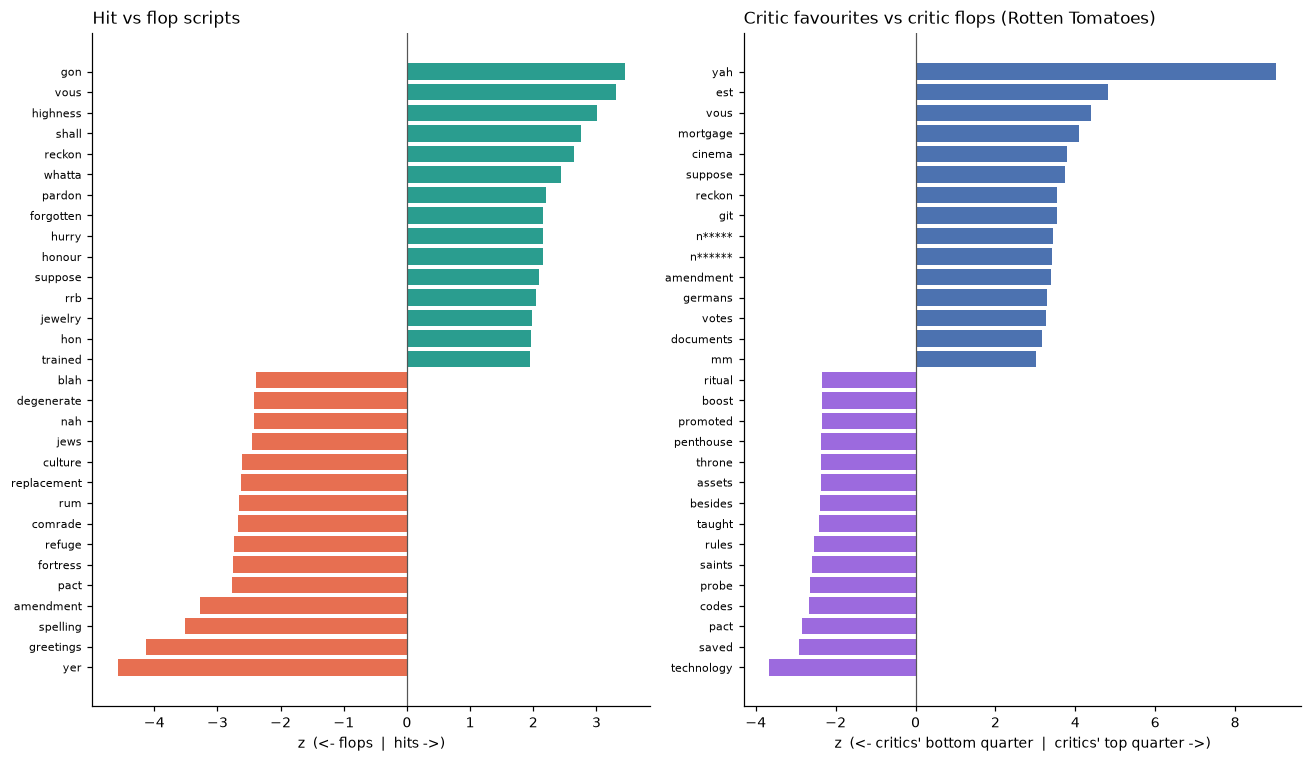

|z| above 1.96 (5% level before multiple testing): money 52, critics 95 of 3,088 words


In [9]:
W = json.load(open(F / "screenplay_words.json"))
names = set().union(*(set(v["names"]) for v in W.values()))
df = Counter(w for v in W.values() for w in v["counts"])
# Plain alphabetic words only: some MovieSum scripts are pre-tokenised ("do n't"), which would make
# "n't" and "''" look like content.
vocab = {w for w, c in df.items() if c >= 50 and w not in names and re.fullmatch(r"[a-z]{2,}", w)}
SLURS = re.compile(r"^(nigg|fag|kike|spic|chink|wetback|retard)")
shown = lambda w: w[0] + "*" * (len(w) - 1) if SLURS.match(w) else w
def corpus(ids):
    out = Counter()
    for t in ids:
        if t in W:
            out.update({w: c for w, c in W[t]["counts"].items() if w in vocab})
    return out
def log_odds(a, b):
    prior = a + b; na, nb, n0 = sum(a.values()), sum(b.values()), sum(prior.values())
    z = {}
    for w, p in prior.items():
        ya, yb = a.get(w, 0), b.get(w, 0)
        dd = math.log((ya + p) / (na + n0 - ya - p)) - math.log((yb + p) / (nb + n0 - yb - p))
        z[w] = dd / math.sqrt(1 / (ya + p) + 1 / (yb + p))
    return pd.Series(z).sort_values()

def plot_words(z, left, right, title, ax, n=15):
    top = pd.concat([z.head(n), z.tail(n)])
    ax.barh([shown(w) for w in top.index], top.values, color=[left[1]] * n + [right[1]] * n)
    ax.axvline(0, color="#555", lw=0.8); ax.set_title(title, loc="left")
    ax.set_xlabel(f"z  (<- {left[0]}  |  {right[0]} ->)"); ax.tick_params(axis="y", labelsize=7)

fig, axes = plt.subplots(1, 2, figsize=(12, 7))
z_money = log_odds(corpus(s[s.group == "hit"].tconst), corpus(s[s.group == "flop"].tconst))
plot_words(z_money, ("flops", FLOP), ("hits", HIT), "Hit vs flop scripts", axes[0])
rt_hi, rt_lo = s.rt.quantile([0.75, 0.25])
z_crit = log_odds(corpus(s[s.rt >= rt_hi].tconst), corpus(s[s.rt <= rt_lo].tconst))
plot_words(z_crit, ("critics' bottom quarter", "#9c6ade"), ("critics' top quarter", "#4c72b0"),
           "Critic favourites vs critic flops (Rotten Tomatoes)", axes[1])
plt.tight_layout(); plt.show()
print(f"|z| above 1.96 (5% level before multiple testing): money {int((z_money.abs() > 1.96).sum())}, "
      f"critics {int((z_crit.abs() > 1.96).sum())} of {len(vocab):,} words")

In [10]:
# A word one film repeats can top a list on its own. For the top words, the film that uses each most
# and its share of all uses across the screenplays:
names_by_id = dict(zip(sp.tconst, sp.movie_name))
def top_film(w):
    uses = {t: v["counts"].get(w, 0) for t, v in W.items()}
    t = max(uses, key=uses.get)
    return names_by_id.get(t, t), uses[t] / max(1, sum(uses.values()))
rows = []
for label, z in (("hits", z_money), ("flops", -z_money), ("critics' top", z_crit), ("critics' bottom", -z_crit)):
    for w in z.sort_values(ascending=False).head(5).index:
        f, share = top_film(w)
        rows.append({"side": label, "word": shown(w), "z": round(abs(z[w]), 2), "film using it most": f,
                     "that film's share": round(share, 2)})
pd.DataFrame(rows)

,side,word,z,film using it most,that film's share
0,hits,gon,3.45,Casino_1995,0.01
1,hits,vous,3.31,Anatomy of a Fall_2023,0.29
2,hits,highness,3.01,Star Wars: Episode I - The Phantom Menace_1999,0.14
3,hits,shall,2.76,Romeo + Juliet_1996,0.01
4,hits,reckon,2.65,Sling Blade_1996,0.20
5,flops,yer,4.58,The Lighthouse_2019,0.13
6,flops,greetings,4.13,Coneheads_1993,0.15
7,flops,spelling,3.51,Bad Words_2013,0.37
8,flops,amendment,3.28,Lincoln_2012,0.37
9,flops,pact,2.76,A Long Way Down_2014,0.12


With thousands of words, some clear |z| = 1.96 by chance, and the table above shows where a single film
carries a word. Read these lists as hints about genre, period and register, not as words that make money.

## 6. Do whole-script embeddings predict profit?

The screenplay vectors (`features/embeddings_hpc/`) are all-MiniLM-L6-v2 embeddings of each script's
passages, averaged per film. The test: cross-validated R² for ln(multiple) from budget, year and genre
alone, then with the first 20 principal components of the script vectors added. A shuffle test (the
vectors moved between films) gives the gain we would expect by chance.

In [11]:
def genre_dummies(frame, min_films=50):
    g = frame.genres.fillna("").str.get_dummies(sep=",")
    return g[[c for c in g if g[c].sum() >= min_films]]

def cv_r2(X, y, seed=SEED, folds=5):
    out = []
    for tr, te in KFold(folds, shuffle=True, random_state=seed).split(X):
        mdl = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25))).fit(X[tr], y[tr])
        out.append(r2_score(y[te], mdl.predict(X[te])))
    return float(np.mean(out))

def embedding_test(frame, V, label, k=20, perms=200, repeats=5):
    base = np.column_stack([frame.log_budget, frame.y, genre_dummies(frame).values])
    y = frame.log_mult.values
    P = PCA(k, random_state=SEED).fit_transform(V)
    b = np.mean([cv_r2(base, y, SEED + r) for r in range(repeats)])
    full = np.mean([cv_r2(np.column_stack([base, P]), y, SEED + r) for r in range(repeats)])
    only = np.mean([cv_r2(P, y, SEED + r) for r in range(repeats)])
    rng = np.random.default_rng(SEED)
    null = [cv_r2(np.column_stack([base, P[rng.permutation(len(y))]]), y) - cv_r2(base, y) for _ in range(perms)]
    gain = full - b
    p = (1 + sum(n >= gain for n in null)) / (1 + perms)
    print(f"{label}: {len(y):,} films | R2 baseline {b:.3f}, {label} only {only:.3f}, "
          f"baseline + {label} {full:.3f} | gain {gain:+.3f}, shuffle p = {p:.3f}")
    return P

ids = pd.read_csv(F / "embeddings_hpc/ids.csv", dtype={"tconst": str})
SV = np.load(F / "embeddings_hpc/script_vectors.npy")
sv_idx = {t: i for i, t in enumerate(ids.tconst)}
se = d[d.tconst.isin(sv_idx)].reset_index(drop=True)
P_script = embedding_test(se, SV[[sv_idx[t] for t in se.tconst]], "script vectors")

script vectors: 1,691 films | R2 baseline 0.091, script vectors only 0.013, baseline + script vectors 0.099 | gain +0.008, shuffle p = 0.005


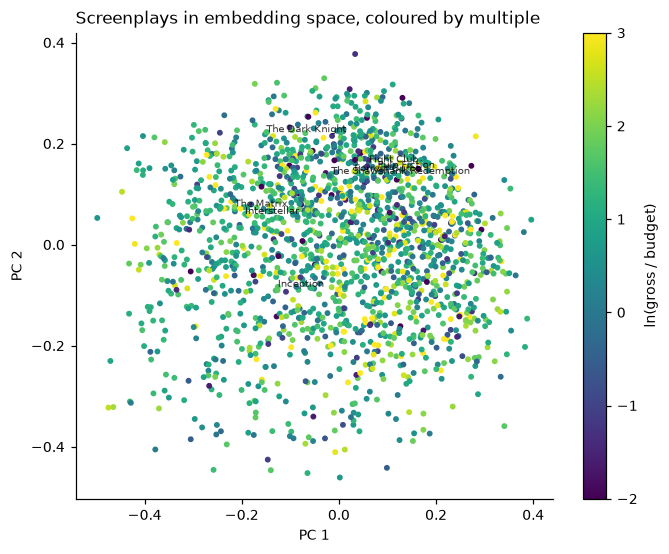

In [12]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(P_script[:, 0], P_script[:, 1], c=se.log_mult, cmap="viridis", s=8, vmin=-2, vmax=3)
plt.colorbar(sc, label="ln(gross / budget)")
for _, r in se.assign(p0=P_script[:, 0], p1=P_script[:, 1]).sort_values("votes").tail(8).iterrows():
    ax.annotate(r.primaryTitle, (r.p0, r.p1), fontsize=6.5, alpha=0.8)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title("Screenplays in embedding space, coloured by multiple", loc="left")
plt.show()

## 7. Weekly reviews vs weekly cinema revenue

We can't do this one with the sources we're allowed to use. Weekly box office comes from Box Office Mojo or
The Numbers, and AGENTS.md rules both out because their terms forbid scraping. The Tag Genome reviews also
carry no dates. Two options if the group wants a weekly view:

- Wikipedia pageviews (daily, from July 2015, CC0, no key) as weekly attention. That's attention, not revenue.
- A licensed weekly box office source, if one turns up whose terms allow it.

## 8. Sentiment of audience reviews vs money and ratings

`vader_mean` is the mean VADER score of a film's first 50 Tag Genome reviews. Does what audiences write line
up with what films earn, and with the scores they and critics give?

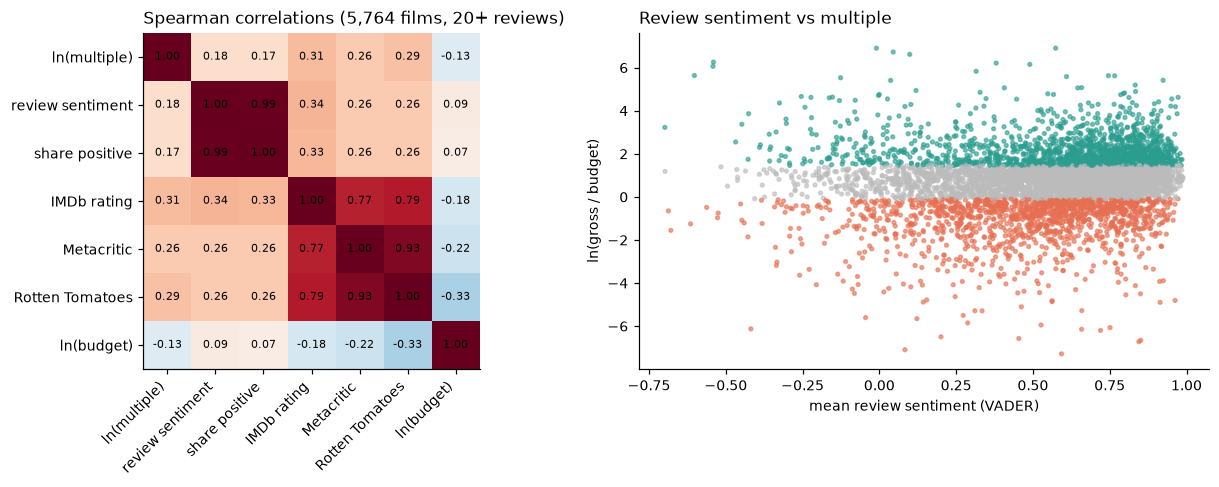

review sentiment vs ln(multiple), net of budget and year: rho = +0.184, p = 5e-45


In [13]:
r8 = d[has_reviews & d.reviews.ge(20)].copy()
cols = {"log_mult": "ln(multiple)", "vader_mean": "review sentiment", "vader_pos_share": "share positive",
        "rating": "IMDb rating", "mc": "Metacritic", "rt": "Rotten Tomatoes", "log_budget": "ln(budget)"}
C = r8[list(cols)].rename(columns=cols).corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.1, 1]})
im = axes[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(C)), C.columns, rotation=45, ha="right"); axes[0].set_yticks(range(len(C)), C.index)
for i in range(len(C)):
    for j in range(len(C)):
        axes[0].text(j, i, f"{C.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
axes[0].set_title(f"Spearman correlations ({len(r8):,} films, 20+ reviews)", loc="left")
colors = r8.group.map({"hit": HIT, "flop": FLOP, "middle": OTHER})
axes[1].scatter(r8.vader_mean, r8.log_mult, c=colors, s=6, alpha=0.6)
axes[1].set_xlabel("mean review sentiment (VADER)"); axes[1].set_ylabel("ln(gross / budget)")
axes[1].set_title("Review sentiment vs multiple", loc="left")
plt.tight_layout(); plt.show()
rho, p = rank_partial(r8.log_mult.values, r8.vader_mean.values, r8[["log_budget", "y"]].values)
print(f"review sentiment vs ln(multiple), net of budget and year: rho = {rho:+.3f}, p = {p:.2g}")

## 9. Reviews in an embedding space

Each film's first 20 reviews are embedded with the same model as the screenplays and averaged. Same test as
section 6. One warning first: reviews are written after release, and some mention the box office
("flopped", "made a fortune"), so a gain here is partly the outcome leaking into the predictor. It tells us
what audiences talk about in successful films, not what predicts success in advance.

In [14]:
rids = pd.read_csv(F / "review_vector_ids.csv", dtype={"tconst": str}).tconst.tolist()
RV = np.load(F / "review_vectors.npy")
rv_idx = {t: i for i, t in enumerate(rids)}
re_ = d[d.tconst.isin(rv_idx)].reset_index(drop=True)
P_rev = embedding_test(re_, RV[[rv_idx[t] for t in re_.tconst]], "review vectors")

review vectors: 5,842 films | R2 baseline 0.084, review vectors only 0.066, baseline + review vectors 0.134 | gain +0.050, shuffle p = 0.005


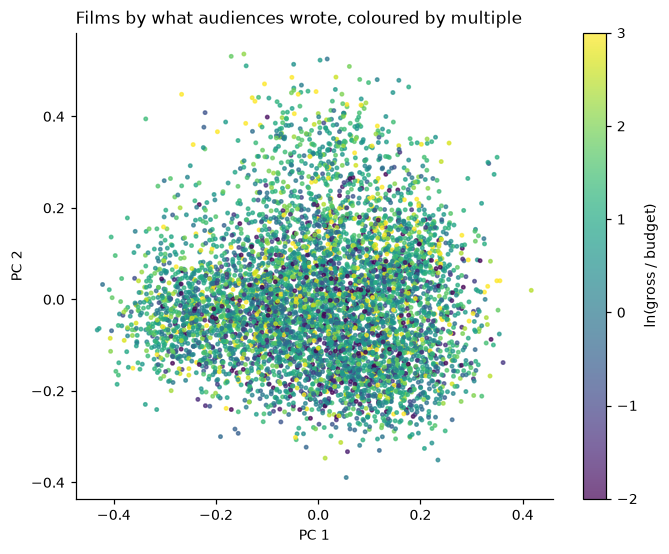

In [15]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(P_rev[:, 0], P_rev[:, 1], c=re_.log_mult, cmap="viridis", s=5, vmin=-2, vmax=3, alpha=0.7)
plt.colorbar(sc, label="ln(gross / budget)")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title("Films by what audiences wrote, coloured by multiple", loc="left")
plt.show()

## 10. Does profit agree with whether people liked the film?

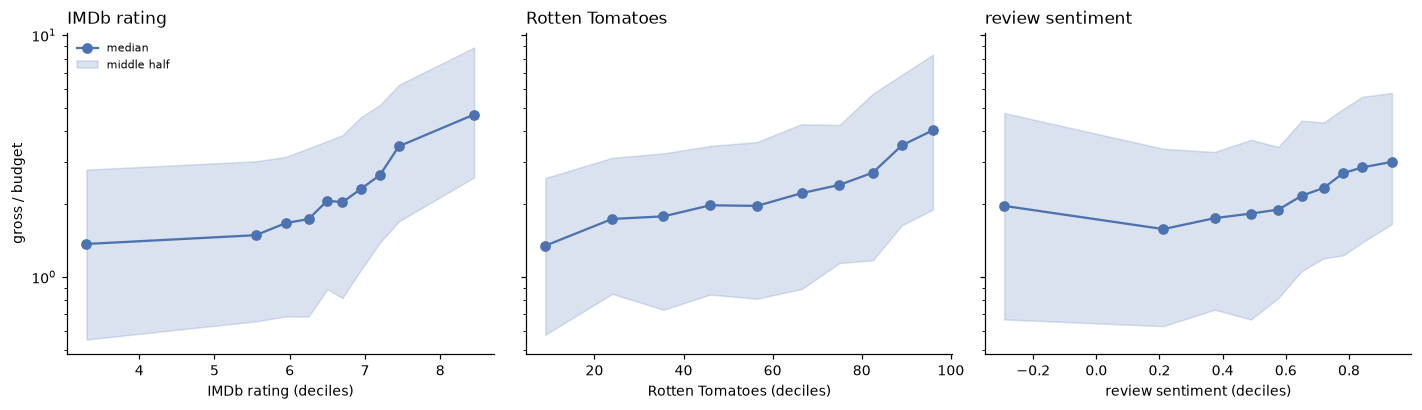

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (col, label) in zip(axes, [("rating", "IMDb rating"), ("rt", "Rotten Tomatoes"), ("vader_mean", "review sentiment")]):
    sub = d.dropna(subset=[col])
    bins = pd.qcut(sub[col], 10, duplicates="drop")
    g = sub.groupby(bins, observed=True).log_mult
    mid = [iv.mid for iv in g.median().index]
    ax.plot(mid, np.exp(g.median()), "o-", color="#4c72b0", label="median")
    ax.fill_between(mid, np.exp(g.quantile(0.25)), np.exp(g.quantile(0.75)), alpha=0.2, color="#4c72b0", label="middle half")
    ax.set_xlabel(f"{label} (deciles)"); ax.set_yscale("log"); ax.set_title(label, loc="left")
axes[0].set_ylabel("gross / budget"); axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## What to take from this

The summary below is printed from the cells above, so it updates when the data does.

In [17]:
best = t.sort_values("p partial").iloc[0]
print(f"- Script features vs multiple, net of budget and year: strongest is {best.feature} "
      f"(rho {best['rho with multiple, net of budget and year']:+.3f}, q {best['q partial']:.2f}); "
      f"{int((t['q partial'] < 0.05).sum())} of {len(t)} pass q < 0.05.")
print(f"- Arc shapes vs multiple: Kruskal-Wallis p = {kw.pvalue:.3f}.")
print(f"- Review sentiment vs multiple, net of budget and year: rho {rho:+.3f}.")
print(f"- Review sentiment vs IMDb rating: rho {C.loc['review sentiment', 'IMDb rating']:+.2f}; "
      f"vs Rotten Tomatoes: {C.loc['review sentiment', 'Rotten Tomatoes']:+.2f}.")

- Script features vs multiple, net of budget and year: strongest is degree centralisation (rho -0.097, q 0.00); 2 of 15 pass q < 0.05.
- Arc shapes vs multiple: Kruskal-Wallis p = 0.987.
- Review sentiment vs multiple, net of budget and year: rho +0.184.
- Review sentiment vs IMDb rating: rho +0.34; vs Rotten Tomatoes: +0.26.
